# Módulo 3 — Diferenciação e raízes unitárias

## Seção 4 — Testes de raiz unitária e estacionariedade: Dickey–Fuller aumentado (ADF) e KPSS

**Estado:** versão para revisão; matemática, testes e Python integrados. **Pré-requisitos:** hipóteses estatísticas elementares, regressão por mínimos quadrados (Módulo 2), estacionariedade (Módulo 1), diferenças e processos integrados (Seções 1–3 deste módulo).

**Fontes e limites de atribuição.** Morettin e Toloi, *Análise de Séries Temporais: modelos lineares univariados*, v. 1, 3ª ed., **Apêndice B, §§B.1–B.3, pp. 411–417**, especialmente equações (B.9)–(B.11) e (B.25)–(B.33), consultadas visualmente nas páginas PDF 430–436, fundamentam a discussão de Dickey–Fuller, raízes unitárias, valores críticos não usuais e extensão aumentada. O mapeamento das videoaulas identifica *Testes para verificar estacionariedade 1 e 2* e a *Aula 7 — ARMA, ARIMA e Testes de Estacionariedade*. **O desenvolvimento do KPSS nesta seção é complemento metodológico**, baseado na formulação clássica de Kwiatkowski, Phillips, Schmidt e Shin (1992), e não deve ser atribuído ao Apêndice B sem localização específica. As simulações, o cálculo manual do caso simples e as interpretações são complementações didáticas originais.

### Objetivos de aprendizagem

Ao concluir esta seção, você deverá: (i) distinguir hipótese nula e alternativa em ADF e KPSS; (ii) compreender a regressão que produz a estatística DF/ADF; (iii) explicar por que valores críticos usuais da distribuição $t$ não servem diretamente; (iv) deduzir os elementos da estatística KPSS; (v) escolher adequadamente constante, tendência e defasagens; (vi) executar os testes com `statsmodels` e interpretar seus resultados sem transformar não rejeição em prova de estacionariedade; (vii) identificar limitações de testes em amostras finitas.

### 1. Motivação: por que olhar um gráfico não é suficiente?

Duas séries podem apresentar trajetórias visualmente parecidas e ser geradas por processos distintos. No Módulo 2, comparamos

$$
X_t=\alpha+\beta t+u_t
$$

com

$$
Z_t=Z_{t-1}+\beta+\varepsilon_t.
$$

No primeiro modelo, depois de retirar a tendência determinística, resta o processo estacionário $u_t$ (sob as hipóteses apropriadas). No segundo, choques se acumulam. Uma trajetória curta, especialmente quando o processo autorregressivo possui $\phi$ próximo de 1, pode não permitir distinguir claramente os dois casos apenas pela inspeção visual.

Os testes ADF e KPSS investigam **hipóteses estatísticas diferentes**. Não são máquinas que revelam infalivelmente a natureza do processo.

### 2. Revisão breve: decisão estatística e o significado de um $p$-valor

Um teste formal começa com uma hipótese nula $H_0$, uma hipótese alternativa $H_1$ e uma estatística calculada dos dados. O **$p$-valor** é a probabilidade, calculada *sob a hipótese nula e as suposições do procedimento*, de observar um resultado pelo menos tão extremo quanto o obtido, na direção relevante. Não é a probabilidade de $H_0$ ser verdadeira.

Para nível de significância $\alpha_{\mathrm{sig}}=0{,}05$:

- Se $p<0{,}05$, rejeitamos $H_0$ ao nível de 5%.
- Se $p\geq0{,}05$, **não rejeitamos** $H_0$; isso não a prova.

O limiar de 5% é convencional, não uma garantia universal de que a decisão esteja correta. A potência de um teste mede sua capacidade de rejeitar a hipótese nula quando uma alternativa específica é verdadeira.

### 3. Dickey–Fuller: da equação AR(1) à regressão em diferenças

Considere um AR(1) simples:

$$
Z_t=\phi Z_{t-1}+\varepsilon_t,
$$

com inovações de média zero e variância positiva. Subtraindo $Z_{t-1}$ dos dois lados:

$$
\begin{aligned}
Z_t-Z_{t-1}
&=(\phi-1)Z_{t-1}+\varepsilon_t.
\end{aligned}
$$

Definindo $\gamma=\phi-1$:

$$
\boxed{\Delta Z_t=\gamma Z_{t-1}+\varepsilon_t.}
$$

No modelo sem termos determinísticos, queremos testar:

$$
H_0:\gamma=0\quad(\phi=1)
$$

contra

$$
H_1:\gamma<0\quad(\phi<1),
$$

sob um conjunto de alternativas estacionárias apropriadas. A condição $\gamma<0$ corresponde a $\phi<1$, mas **a estacionariedade do AR(1) causal também exige $\phi>-1$**. Na prática, a alternativa é interpretada no contexto de modelos estáveis e bem especificados; alternativas explosivas não ficam automaticamente resolvidas por um teste unilateral de raiz unitária.

O coeficiente $\widehat\gamma$ pode ser obtido por mínimos quadrados da regressão de $\Delta Z_t$ em $Z_{t-1}$. A estatística central compara sua estimativa com o valor nulo:

$$
\tau_{DF}=\frac{\widehat\gamma}{\mathrm{ep}(\widehat\gamma)}.
$$

**Por que não utilizar a tabela $t$ de Student habitual?** Sob $H_0$, $Z_t$ possui raiz unitária e os regressores não seguem a estrutura estacionária que fundamenta a aproximação usual. A distribuição limite da estatística é **não padrão** e depende da escolha dos termos determinísticos. Por isso, empregam-se valores críticos e aproximações de $p$-valor específicos de Dickey–Fuller, como discutido no Apêndice B do livro.

#### 3.1 Exemplo numérico de um coeficiente, sem tabela de valores críticos

Considere cinco observações artificiais:

$$
(z_0,z_1,z_2,z_3,z_4)=(1,2,1,1,0).
$$

A regressão sem intercepto e sem defasagens adicionais utiliza

$$
\mathbf x=(z_0,z_1,z_2,z_3)=(1,2,1,1)
$$

e

$$
\mathbf y=(\Delta z_1,\ldots,\Delta z_4)=(1,-1,0,-1).
$$

O estimador de mínimos quadrados para $y_i=\gamma x_i+u_i$ é

$$
\widehat\gamma=
\frac{\sum_i x_i y_i}{\sum_i x_i^2}
=\frac{1-2+0-1}{1+4+1+1}
=-\frac27.
$$

Essa conta demonstra como o coeficiente é estimado. **Não é suficiente para concluir se existe raiz unitária**: ainda precisamos estimar seu erro padrão, obter a estatística, definir a especificação do teste e compará-la à distribuição apropriada.

### 4. O teste Dickey–Fuller aumentado (ADF)

Os erros de um modelo simples podem apresentar dependência adicional. O ADF incorpora defasagens das primeiras diferenças para lidar com a autocorrelação residual que, caso ignorada, comprometeria a aproximação do teste.

Uma especificação com constante e tendência linear é

$$
\boxed{
\Delta Z_t
=c+\delta t+\gamma Z_{t-1}
+\sum_{j=1}^{p}\psi_j\Delta Z_{t-j}+u_t.
}
$$

Cada termo possui um papel:

- $\Delta Z_t$: variação atual da série;
- $c$: termo constante na regressão;
- $\delta t$: tendência determinística incluída quando justificável;
- $Z_{t-1}$: nível defasado sobre o qual incide o coeficiente testado;
- $\Delta Z_{t-j}$: diferenças defasadas que absorvem dependência serial de curto prazo;
- $u_t$: erro que deve satisfazer condições apropriadas para a inferência;
- $p$: número de defasagens adicionais, distinto da ordem de integração $d$.

A hipótese central permanece

$$
H_0:\gamma=0,
$$

contra a alternativa de ausência de raiz unitária na especificação escolhida. **Uma rejeição com tendência incluída pode indicar estacionariedade ao redor de tendência determinística; não deve ser descrita simplesmente como estacionariedade em nível sem retirar a tendência.**

#### 4.1 Três escolhas para os termos determinísticos

| Especificação | Regressão ADF inclui | Interpretação da alternativa no contexto adequado |
|---|---|---|
| `regression='n'` | Nenhuma constante ou tendência | Estacionariedade em torno de zero |
| `regression='c'` | Constante | Estacionariedade em torno de média constante |
| `regression='ct'` | Constante e tendência linear | Estacionariedade em torno de tendência linear |

A escolha deve se basear no modelo substantivo, na inspeção responsável dos dados e na justificativa estatística, não em testar repetidamente especificações até obter $p<0{,}05$. A hipótese nula e as distribuições de referência mudam com a especificação.

#### 4.2 Quantas diferenças defasadas devem entrar?

Poucas defasagens podem deixar dependência serial no erro; muitas reduzem os graus de liberdade e a potência. `autolag='AIC'`, quando usado, seleciona a ordem a partir de um critério de informação; não é uma verdade matemática acerca do número exato de defasagens da realidade. O resultado deve informar quantas foram selecionadas, e a seleção deve se restringir aos dados disponíveis para o momento de análise.

### 5. Teste KPSS: inverter a hipótese nula

O teste de **Kwiatkowski–Phillips–Schmidt–Shin (KPSS)** foi desenvolvido para investigar uma hipótese nula de estacionariedade ao redor de um nível ou de uma tendência determinística, conforme a especificação.

Na modalidade de nível:

$$
H_0:\text{a série é estacionária em torno de uma constante}.
$$

Na modalidade com tendência:

$$
H_0:\text{a série é estacionária em torno de uma tendência determinística linear}.
$$

A hipótese alternativa do procedimento clássico envolve um componente não estacionário do tipo passeio aleatório. Isso não significa que o teste distinga automaticamente todas as formas possíveis de não estacionariedade.

#### 5.1 Decomposição motivadora

Uma construção utilizada para compreender o teste é

$$
Z_t=\delta t+r_t+u_t,
$$

com $u_t$ estacionário e o componente de nível evoluindo como

$$
r_t=r_{t-1}+\eta_t,
\qquad \mathrm{Var}(\eta_t)=\sigma_\eta^2.
$$

Se $\sigma_\eta^2=0$ e a condição inicial é fixa, o componente de nível não varia aleatoriamente e permanece apenas a parte estacionária ao redor dos termos determinísticos. Se $\sigma_\eta^2>0$, o nível acumula inovações. O KPSS constrói uma estatística sensível a esse comportamento.

#### 5.2 Como surge a estatística

Primeiro, ajustamos os termos determinísticos compatíveis com a hipótese nula: constante (KPSS de nível) ou constante e tendência (KPSS de tendência). Denote por $e_t$ os resíduos.

Em seguida, definimos as somas parciais:

$$
S_t=\sum_{i=1}^{t}e_i,\qquad t=1,\ldots,n.
$$

A estatística é da forma

$$
\boxed{
\mathrm{KPSS}=
\frac{1}{n^2\widehat\omega^2}
\sum_{t=1}^{n}S_t^2.
}
$$

Aqui, $\widehat\omega^2$ é uma estimativa da **variância de longo prazo**, que incorpora autocovariâncias dos resíduos, não apenas sua variância instantânea. Uma forma usual, com truncamento $\ell$ e pesos de Bartlett, é

$$
\widehat\omega^2=\widehat\gamma(0)+
2\sum_{j=1}^{\ell}
\left(1-\frac{j}{\ell+1}\right)\widehat\gamma(j),
$$

em que

$$
\widehat\gamma(j)=\frac1n\sum_{t=j+1}^{n}e_t e_{t-j}.
$$

**Interpretação intuitiva:** se os resíduos têm flutuações estacionárias de curta duração, suas somas parciais apresentam um comportamento compatível com a escala pressuposta sob a hipótese nula. Uma mudança persistente do nível tende a produzir somas parciais grandes, aumentando a estatística. A distribuição limite do KPSS também é não usual e depende da especificação.

O parâmetro $\ell$ controla quantas autocovariâncias entram na estimativa de longo prazo. Sua escolha altera a estatística, especialmente em amostras pequenas. `nlags='auto'` fornece uma regra automática implementada pela biblioteca, mas não dispensa análise crítica.

### 6. ADF e KPSS: como interpretar os resultados em conjunto

| ADF | KPSS | Leitura inicial, **não definitiva** |
|---|---|---|
| Rejeita raiz unitária | Não rejeita estacionariedade | Evidência compatível com estacionariedade na especificação examinada |
| Não rejeita raiz unitária | Rejeita estacionariedade | Evidência compatível com não estacionariedade e possível integração |
| Não rejeita raiz unitária | Não rejeita estacionariedade | Evidência inconclusiva; pode haver baixa potência ou amostra insuficiente |
| Rejeita raiz unitária | Rejeita estacionariedade | Hipóteses/modelos podem estar inadequados; investigar tendências, quebras e dependência |

**Atenção:** os testes não são complementos lógicos perfeitos. Diferem nas hipóteses e nas suposições. A combinação de seus resultados ajuda a investigar o processo, mas não oferece uma prova formal de ordem de integração.

### 7. Python integrado — execução e interpretação

Utilizaremos `NumPy` para simular séries e `statsmodels.tsa.stattools` para calcular ADF e KPSS. A classe de dados utilizada é uma sequência numérica unidimensional, sem valores ausentes. Os exemplos foram testados com séries sintéticas; dados reais exigem atenção à frequência, falhas e intervenções.

In [ ]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss

rng = np.random.default_rng(20261116)
n = 500
t = np.arange(n)

# AR(1) com phi = 0,55, iniciado em zero
inov = rng.normal(size=n)
ar = np.zeros(n)
for i in range(1, n):
    ar[i] = 0.55 * ar[i - 1] + inov[i]

# Passeio aleatório: soma cumulativa de inovações independentes
passeio = np.cumsum(rng.normal(size=n))

# Modelo estacionário ao redor de tendência determinística
com_tendencia = 4 + 0.03 * t + ar

casos = [
    ("AR(1) estacionário", ar, "c"),
    ("Passeio aleatório", passeio, "c"),
    ("Estacionário em torno de tendência", com_tendencia, "ct"),
]

for nome, serie, especificacao in casos:
    adf = adfuller(
        serie, maxlag=12,
        regression=especificacao, autolag="AIC"
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kp = kpss(serie, regression=especificacao, nlags="auto")
    print(f"\n{nome}")
    print("ADF:", adf[0], "p:", adf[1], "lags:", adf[2])
    print("KPSS:", kp[0], "p:", kp[1], "lags:", kp[2])

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, (nome, serie, _) in zip(axes, casos):
    ax.plot(t, serie)
    ax.set_title(nome)
    ax.set_ylabel("Valor")
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Instante t")
fig.tight_layout()
plt.show()


**Sobre as funções:** `adfuller` retorna, entre outros elementos, estatística, $p$-valor aproximado, quantidade de defasagens e quantidade de observações efetivamente usadas. `kpss` retorna estatística, $p$-valor tabulado/interpolado e defasagens usadas para a variância de longo prazo. Os componentes desses retornos não são intercambiáveis. O procedimento `kpss` aceita `regression='c'` e `regression='ct'`, mas não `'n'`.

#### 7.1 Resultados obtidos em execução com semente fixa

| Processo sintético | ADF (estatística; $p$ aproximado) | KPSS (estatística; $p$ reportado) |
|---|---|---|
| AR(1) com $\phi=0{,}55$ | $-11{,}912$; $p$ muito pequeno | $0{,}140$; $p\geq0{,}10$ na tabela |
| Passeio aleatório | $-1{,}055$; $p\approx0{,}733$ | $3{,}685$; $p\leq0{,}01$ na tabela |
| Tendência determinística + AR(1), com `'ct'` | $-11{,}934$; $p$ muito pequeno | $0{,}056$; $p\geq0{,}10$ na tabela |

Os valores são resultados **empíricos** de uma amostra pseudoaleatória específica, não propriedades exatas dos testes. Os $p$-valores KPSS apresentados pela biblioteca podem atingir os limites da sua tabela de referência; nesse caso, `0.10` significa **pelo menos 0,10** e `0.01` significa **no máximo 0,01**, e não os valores exatos. Também não devemos relatar o $p$-valor ADF impresso como `0.0` como probabilidade matematicamente igual a zero.

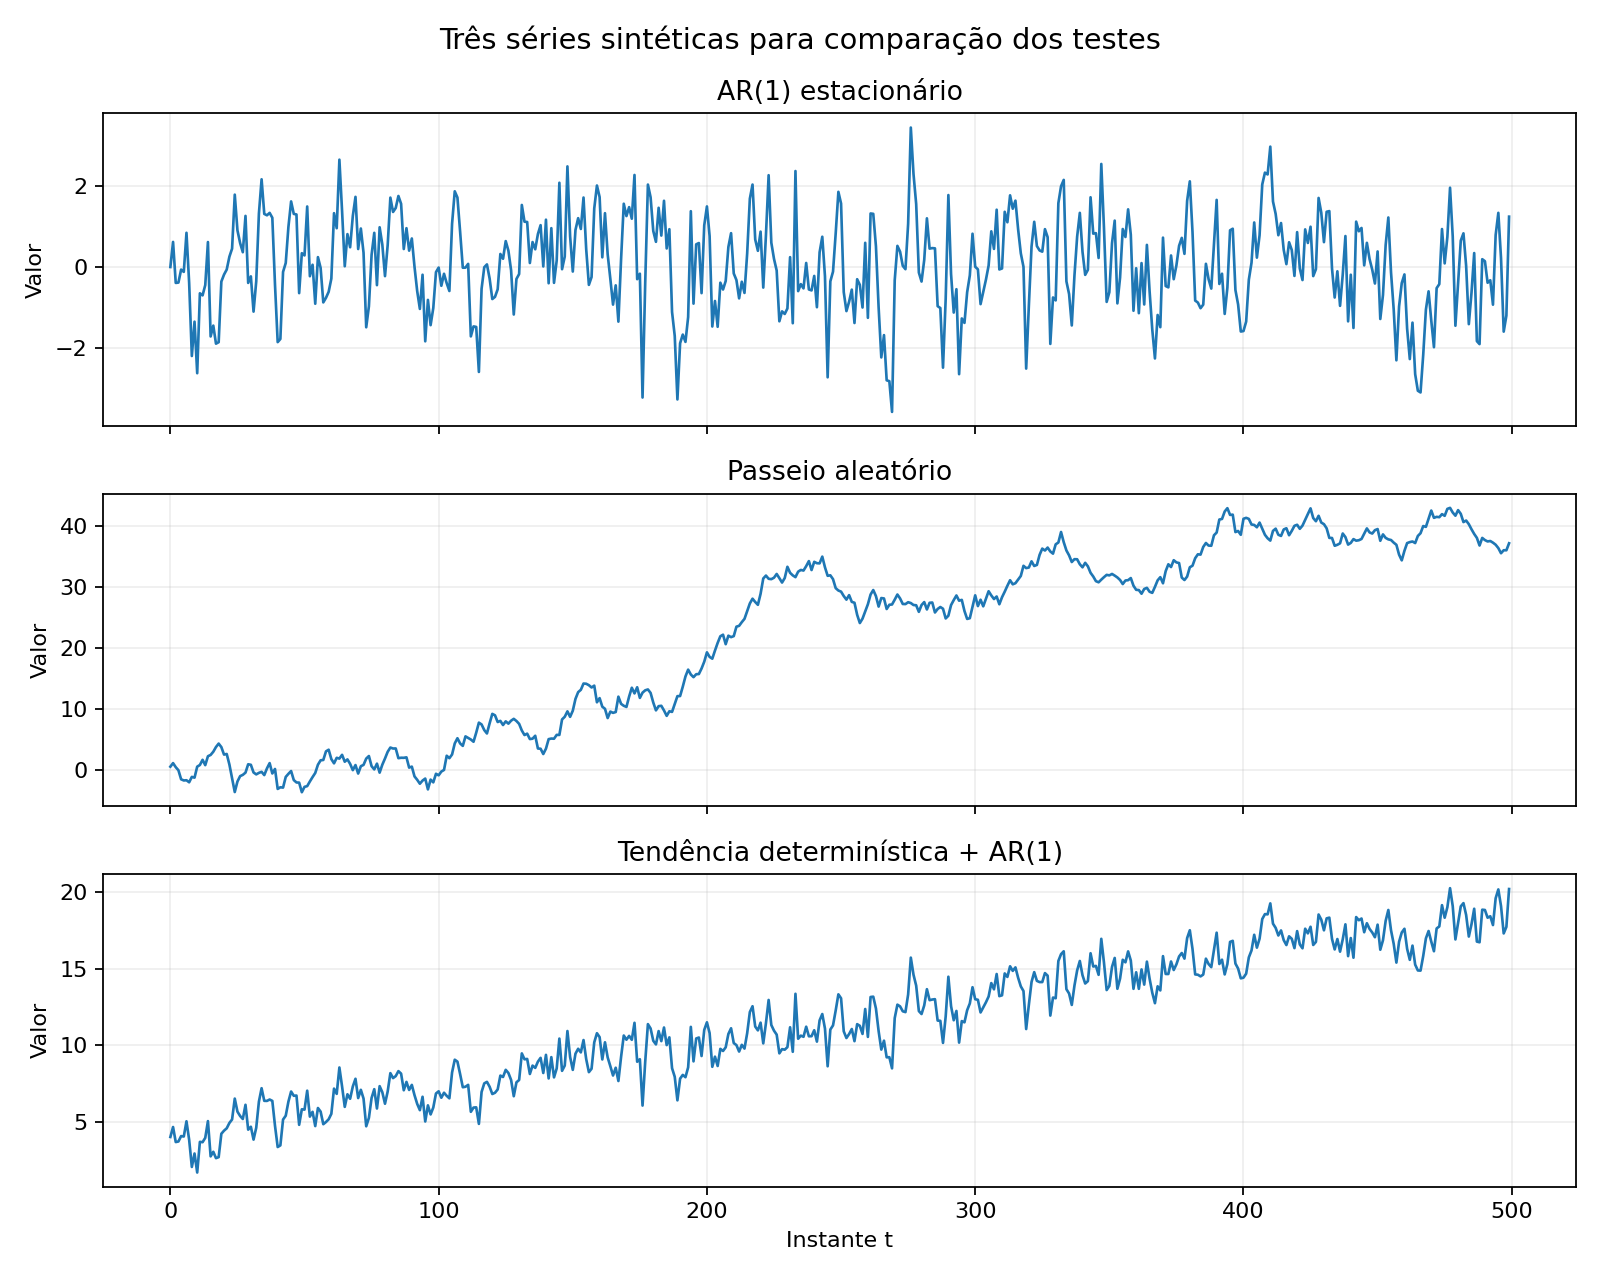

*Figura 1 — Processos simulados para comparar as hipóteses dos testes. A série com tendência deve ser analisada com especificação que inclua tendência para investigar estacionariedade ao redor dessa componente.*

### 8. Conferência manual de uma versão elementar de Dickey–Fuller

Para compreender a relação entre regressão e estatística de teste, podemos calcular uma versão **sem constante, sem tendência e sem defasagens aumentadas**:

$$
\Delta Z_t=\gamma Z_{t-1}+u_t.
$$

Estimamos

$$
\widehat\gamma=
\frac{\sum_{t=2}^{n}Z_{t-1}\Delta Z_t}
{\sum_{t=2}^{n}Z_{t-1}^2}.
$$

Os resíduos são $\widehat u_t=\Delta Z_t-\widehat\gamma Z_{t-1}$. O estimador de variância residual para essa regressão com um parâmetro e $n-1$ pares é

$$
\widehat\sigma_u^2=
\frac{\sum_{t=2}^{n}\widehat u_t^2}{n-2}.
$$

Logo,

$$
\tau_{DF}=
\frac{\widehat\gamma}
{\sqrt{\widehat\sigma_u^2/\sum_{t=2}^{n}Z_{t-1}^2}}.
$$

Em Python, podemos comparar nosso cálculo com `adfuller` sem defasagens:

In [ ]:
x = passeio[:-1]                # Z_(t-1)
delta = np.diff(passeio)       # ΔZ_t

gamma_hat = np.dot(x, delta) / np.dot(x, x)
residuos = delta - gamma_hat * x
sigma2 = np.dot(residuos, residuos) / (len(delta) - 1)
erro_padrao = np.sqrt(sigma2 / np.dot(x, x))
t_manual = gamma_hat / erro_padrao

t_biblioteca = adfuller(
    passeio, maxlag=0, regression="n", autolag=None
)[0]

print("Estatística manual:", t_manual)
print("Estatística da biblioteca:", t_biblioteca)
print("Diferença absoluta:", abs(t_manual - t_biblioteca))


No experimento executado, os dois valores foram iguais até a precisão numérica mostrada, aproximadamente **0,7715**. Essa conferência valida o cálculo computacional dessa configuração particular, **não demonstra** que sua distribuição de referência seja $t$ de Student.

### 9. Limitações, advertências e boas práticas

**Baixa potência.** Em amostras pequenas, ADF pode deixar de rejeitar raízes unitárias quando o processo é estacionário, mas bastante persistente ($\phi$ próximo de 1).

**Tendência mal especificada.** Usar constante quando o modelo requer constante e tendência pode distorcer a interpretação; incluir termos sem justificativa também reduz potência.

**Quebras estruturais.** Mudanças bruscas de nível ou inclinação podem afetar os dois testes. Muitas vezes é apropriado investigar intervenção, quebra ou mudanças de regime antes de concluir pela diferenciação.

**Autocorrelação e heterocedasticidade.** O número de defasagens do ADF e a estimativa de variância de longo prazo do KPSS exigem atenção. Os procedimentos clássicos não resolvem automaticamente toda forma de heterocedasticidade ou dependência.

**Amostragem e sazonalidade.** Dados com frequências irregulares, valores ausentes ou raízes sazonais podem exigir métodos apropriados. ADF e KPSS usuais investigam aspectos de raiz unitária ordinária e estacionariedade de nível/tendência, não substituem um estudo específico de raízes sazonais.

**Cuidado com aplicações preditivas.** Quando um teste é usado para decidir transformação dentro de uma avaliação de previsão, a decisão deve ser tomada apenas com o conjunto disponível na etapa de treinamento, sem consultar a amostra futura.

### 10. Exercícios de fixação e aprofundamento

1. **Conceitual:** explique por que um ADF com $p=0{,}30$ não demonstra que a série tem raiz unitária.
2. **Conceitual:** um KPSS com $p<0{,}01$ rejeitou a hipótese nula. O que foi rejeitado? Por que isso não prova automaticamente que $Z_t\sim I(1)$?
3. **Álgebra:** deduza $\Delta Z_t=\gamma Z_{t-1}+\varepsilon_t$ a partir de $Z_t=\phi Z_{t-1}+\varepsilon_t$; identifique o valor de $\gamma$ sob raiz unitária.
4. **Regressão:** use o exemplo numérico da §3.1 para calcular todos os resíduos e a soma dos quadrados residual.
5. **Programação orientada:** execute o código substituindo $\phi=0{,}55$ por $\phi=0{,}95$ no AR(1), mantendo $n=500$; compare decisões e explique por que um resultado isolado não estabelece a natureza do processo.
6. **Avaliação crítica:** repita os testes da série com tendência usando `'c'` em vez de `'ct'`. Explique por que as duas configurações não respondem exatamente à mesma pergunta.
7. **Aprofundamento:** derive a forma de uma estimativa da variância de longo prazo com truncamento $\ell=2$ e pesos de Bartlett, identificando os coeficientes de $\widehat\gamma(1)$ e $\widehat\gamma(2)$.

**Pistas selecionadas:** exercício 3: $\gamma=\phi-1$; exercício 7: os pesos são $2/3$ e $1/3$, e cada autocovariância positiva entra multiplicada também pelo fator 2 da simetria.

### 11. Síntese e bibliografia

O ADF começa com a hipótese nula de raiz unitária; o KPSS, com a hipótese nula de estacionariedade em torno dos termos determinísticos selecionados. Essa diferença permite usá-los como verificações complementares, sempre com atenção à especificação, à potência e à qualidade dos dados. Nenhum deles transforma não rejeição em certeza.

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed., v. 1. São Paulo: Blucher, 2018. Apêndice B, §§B.1–B.3, pp. 411–417. **Trechos consultados visualmente; base direta para o DF/ADF.**
- KWIATKOWSKI, D.; PHILLIPS, P. C. B.; SCHMIDT, P.; SHIN, Y. *Testing the null hypothesis of stationarity against the alternative of a unit root*. Journal of Econometrics, v. 54, n. 1–3, pp. 159–178, 1992. **Referência complementar clássica identificada para o KPSS; não consultada diretamente no acervo deste projeto nesta etapa.**
- *Mapeamento de conteúdos para iniciação científica: séries temporais*, documento local, registros de testes ADF e KPSS.
- Complementações didáticas originais: exemplo de regressão manual, integração com Python, experimentos sintéticos, exercício de interpretação dos retornos do `statsmodels`.

**Continuidade curricular:** a Seção 5 do módulo poderá reunir decisões de diferenciação, diagnóstico de sobrediferenciação e exercícios integradores antes de aprofundar a ACF e a PACF no Módulo 4.